# Étape 4 · Analyse descriptive

Ce que disent les données du challenge, et les figures des pistes.

À lancer dans le projet complet (archive `05-interpretation_D1_scientist_projet-complet_v1.zip`), avec les données brutes placées comme le dit `data/raw/LISEZ-MOI.md`.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

racine = Path.cwd()
while not (racine / "scripts").is_dir() and racine != racine.parent:
    racine = racine.parent
os.chdir(racine)
sys.path.insert(0, "scripts")

In [2]:
def montrer_figures(depuis, dossiers=("analyse/figures", "analyse", "analyse/fiches"), maxi=8):
    vues = sorted((p for d in dossiers for p in Path(d).glob("*.png") if p.stat().st_mtime >= depuis), key=lambda p: p.name)
    for p in vues[:maxi]:
        print(p)
        display(Image(filename=str(p), width=760))

## 1. Analyse descriptive

`scripts/analyse_presco.py`

In [3]:
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {y: y[2:4] + "/" + y[7:] for y in YEARS}

In [4]:
def get(d, table, sexe="T", statut="Total", **f):
    x = d[(d.table == table) & (d.sexe == sexe) & (d.statut == statut)]
    for k, v in f.items():
        x = x[x[k] == v]
    return x

In [5]:
def wide(x, index="region"):
    return x.pivot_table(index=index, columns="annee", values="valeur")[YEARS]

In [6]:
def main():
    d = pd.read_csv(sys.argv[1])
    out = sys.argv[2].rstrip("/")
    pd.set_option("display.width", 250)
    pd.set_option("display.max_columns", 30)

    nat = pd.DataFrame({
        "eleves_primaire": wide(get(d, "E1", region="NATIONAL")).iloc[0],
        "ecoles_primaires": wide(get(d, "E13", region="NATIONAL")).iloc[0],
        "nouveaux_CP1": wide(get(d, "E5", region="NATIONAL")).iloc[0],
        "TBS_%": wide(get(d, "E7", region="NATIONAL")).iloc[0],
        "TAP_%": wide(get(d, "E8", region="NATIONAL")).iloc[0],
        "TAP_garcons_%": wide(get(d, "E8", sexe="G", region="NATIONAL")).iloc[0],
        "TAP_filles_%": wide(get(d, "E8", sexe="F", region="NATIONAL")).iloc[0],
        "reussite_CEP_%": wide(get(d, "E9", region="NATIONAL")).iloc[0],
    })
    nat.index = [SHORT[y] for y in nat.index]
    nat.to_csv(f"{out}/A_tendances_nationales.csv")
    print("\n=== A. Tendances nationales (primaire) ===")
    print(nat.round(1).to_string())

    eff = wide(get(d, "E1")).drop("NATIONAL")
    eco = wide(get(d, "E13")).drop("NATIONAL")
    tap = wide(get(d, "E8")).drop("NATIONAL")
    drawdown = (eff / eff.cummax(axis=1) - 1).min(axis=1)
    reg = pd.DataFrame({
        "eleves_max": eff.max(axis=1).astype(int),
        "annee_max": eff.idxmax(axis=1).map(SHORT),
        "eleves_2024_25": eff["2024-2025"].astype(int),
    })
    reg["pire_chute_%"] = (drawdown * 100).round(1)
    reg["annee_pire_chute"] = (eff / eff.cummax(axis=1) - 1).idxmin(axis=1).map(SHORT)
    reg["2024_25_vs_max_%"] = ((reg.eleves_2024_25 / reg.eleves_max - 1) * 100).round(1)
    reg["ecoles_max"] = eco.max(axis=1).astype(int)
    reg["ecoles_2024_25"] = eco["2024-2025"].astype(int)
    reg["ecoles_vs_max_%"] = ((reg.ecoles_2024_25 / reg.ecoles_max - 1) * 100).round(1)
    reg["TAP_15_16"] = tap["2015-2016"]
    reg["TAP_21_22"] = tap["2021-2022"]
    reg["TAP_24_25"] = tap["2024-2025"]
    reg["TAP_ecart_pts"] = (tap["2024-2025"] - tap["2015-2016"]).round(1)
    reg = reg.sort_values("TAP_ecart_pts")
    reg.to_csv(f"{out}/B_choc_et_reprise_par_region.csv")
    print("\n=== B. Choc et reprise par région (primaire) ===")
    print(reg.to_string())

    ni = wide(get(d, "E5")).drop("NATIONAL")
    nat_e = wide(get(d, "E1", region="NATIONAL")).iloc[0]
    nat_ni = wide(get(d, "E5", region="NATIONAL")).iloc[0]
    ex = pd.DataFrame(index=eff.index)
    for t0, t1 in zip(YEARS[:-1], YEARS[1:]):
        ex[SHORT[t0] + "→" + SHORT[t1]] = ((1 - (eff[t1] - ni[t1]) / eff[t0]) * 100).round(1)
    ex.loc["NATIONAL"] = [round((1 - (nat_e[t1] - nat_ni[t1]) / nat_e[t0]) * 100, 1) for t0, t1 in zip(YEARS[:-1], YEARS[1:])]
    ex.to_csv(f"{out}/C_sorties_apparentes_par_region.csv")
    print("\n=== C. Sorties apparentes (% des élèves d'une année absents l'année suivante, hors nouveaux CP1) ===")
    print("    inclut les fins de CM2 normales, les abandons et les départs nets vers d'autres régions")
    print(ex.to_string())

    e4 = d[(d.table == "E4") & d.statut.isin(["Public", "Prive"]) & (d.niveau != "Total")]
    g = e4.groupby(["sexe", "niveau", "annee"]).valeur.sum().unstack("annee")[YEARS]
    grades = ["CP1", "CP2", "CE1", "CE2", "CM1", "CM2"]
    rows = []
    for sx in ["G", "F", "T"]:
        for a, b in zip(grades[:-1], grades[1:]):
            r = [g.loc[(sx, b), t1] / g.loc[(sx, a), t0] for t0, t1 in zip(YEARS[:-1], YEARS[1:])]
            rows.append([sx, f"{a}→{b}"] + [round(v * 100, 1) for v in r])
    flows = pd.DataFrame(rows, columns=["sexe", "passage"] + [SHORT[t1] for t1 in YEARS[1:]])
    flows.to_csv(f"{out}/D_passages_apparents_par_niveau.csv", index=False)
    print("\n=== D. Passages apparents d'un niveau au suivant, national (effectif niveau+1 l'année t+1 / effectif niveau l'année t, en %) ===")
    print(flows[flows.sexe == "T"].to_string(index=False))
    surv = []
    for k in range(5):
        t0, t5 = YEARS[k], YEARS[k + 5]
        surv.append({"cohorte_CP1": SHORT[t0], "CM2_en": SHORT[t5],
                     **{f"survie_apparente_{sx}_%": round(g.loc[(sx, "CM2"), t5] / g.loc[(sx, "CP1"), t0] * 100, 1)
                        for sx in ["G", "F", "T"]}})
    surv = pd.DataFrame(surv)
    surv.to_csv(f"{out}/D_survie_apparente_CP1_CM2.csv", index=False)
    print("\nSurvie apparente CP1 -> CM2 cinq ans plus tard (effectif CM2 / effectif CP1) :")
    print(surv.to_string(index=False))

    ips = wide(get(d, "E12")).round(2)
    ips.columns = [SHORT[c] for c in ips.columns]
    tapg = wide(get(d, "E8", sexe="G"))["2024-2025"]
    tapf = wide(get(d, "E8", sexe="F"))["2024-2025"]
    gender = pd.DataFrame({"TAP_garcons_24_25": tapg, "TAP_filles_24_25": tapf,
                           "IPS_TAP_15_16": ips["15/16"], "IPS_TAP_24_25": ips["24/25"]}).sort_values("IPS_TAP_24_25")
    gender.to_csv(f"{out}/E_parite_achevement.csv")
    print("\n=== E. Parité filles/garçons de l'achèvement (IPS du TAP : >1 = filles devant) ===")
    print(gender.to_string())

    dl_e = np.log(eff[YEARS[1:]].values / eff[YEARS[:-1]].values).ravel()
    dl_s = np.log(eco[YEARS[1:]].values / eco[YEARS[:-1]].values).ravel()
    slope, intercept = np.polyfit(dl_s, dl_e, 1)
    r2 = np.corrcoef(dl_s, dl_e)[0, 1] ** 2
    print("\n=== F. Écoles en moins et élèves en moins (variations annuelles, 13 régions x 9 années) ===")
    print(f"pente = {slope:.2f} (1 % d'écoles en moins va avec {slope:.2f} % d'élèves en moins), R² = {r2:.2f}, n = {len(dl_e)}")

    err = []
    for t0, t1 in zip(YEARS[:-1], YEARS[1:]):
        e_ = (tap[t1] - tap[t0]).abs()
        err.append({"annee_predite": SHORT[t1], "erreur_moyenne_pts": round(e_.mean(), 2), "erreur_max_pts": round(e_.max(), 1),
                    "region_erreur_max": e_.idxmax()})
    err = pd.DataFrame(err)
    err.to_csv(f"{out}/G_persistance_TAP.csv", index=False)
    print("\n=== G. Règle « comme l'an passé » appliquée au TAP régional : erreur absolue (points) ===")
    print(err.to_string(index=False))
    print(f"erreur moyenne sur toutes les années : {err.erreur_moyenne_pts.mean():.2f} points")

In [7]:
lancer_analyse_presco = main
t0 = time.time()
sys.argv = ['analyse_presco.py', 'data/tidy/presco_tidy.csv', 'analyse/']
lancer_analyse_presco()
montrer_figures(t0)


=== A. Tendances nationales (primaire) ===
       eleves_primaire  ecoles_primaires  nouveaux_CP1  TBS_%  TAP_%  TAP_garcons_%  TAP_filles_%  reussite_CEP_%
15/16        2873049.0           14655.0      605085.0   86.1   58.2           55.3          61.3            62.1
16/17        3040802.0           15330.0      634548.0   88.5   60.3           56.6          64.3            73.7
17/18        3206019.0           15756.0      661578.0   90.7   63.0           58.8          67.6            65.8
18/19        3233784.0           15345.0      632117.0   88.8   61.7           57.4          66.3            55.2
19/20        3240347.0           14863.0      625589.0   86.6   60.3           56.0          64.9            66.0
20/21        3289736.0           15077.0      655449.0   86.1   62.4           57.3          67.7            60.0
21/22        3174946.0           14427.0      635757.0   85.8   62.0           57.5          66.5            63.3
22/23        2835544.0           12780.0    

## 2. Figures 01 à 07

`scripts/figures_pistes.py`

In [8]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = [y[2:4] + "/" + y[7:] for y in YEARS]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
})

In [9]:
def title(fig, main, sub, source=True):
    fig.text(0.01, 0.985, main, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.945, sub, fontsize=9.5, color=INK2, va="top")
    if source:
        fig.text(0.01, 0.01, "Source : données du Data Challenge Burkina (Presco), calculs de l'équipe.",
                 fontsize=7.5, color=MUTED)

In [10]:
NAMES = {"BOUCLE DU MOUHOUN": "Boucle du Mouhoun", "CASCADES": "Cascades", "CENTRE": "Centre",
         "CENTRE-EST": "Centre-Est", "CENTRE-NORD": "Centre-Nord", "CENTRE-OUEST": "Centre-Ouest",
         "CENTRE-SUD": "Centre-Sud", "EST": "Est", "HAUTS-BASSINS": "Hauts-Bassins", "NORD": "Nord",
         "PLATEAU CENTRAL": "Plateau-Central", "SAHEL": "Sahel", "SUD-OUEST": "Sud-Ouest"}

In [11]:
def fr(v, nd=1, sign=False):
    return (f"{v:+.{nd}f}" if sign else f"{v:.{nd}f}").replace(".", ",")

In [12]:
def fmt_k(v):
    return f"{v / 1000:,.0f} k".replace(",", " ")

In [13]:
def main():
    d = pd.read_csv(sys.argv[1])
    a = sys.argv[2].rstrip("/")
    out = sys.argv[3].rstrip("/")
    os.makedirs(out, exist_ok=True)
    p = pd.read_csv(f"{a}/panel_region_annee.csv")
    nat = p[p.region == "NATIONAL"].set_index("annee").loc[YEARS]
    reg = p[p.region != "NATIONAL"]

    e4 = d[(d.table == "E4") & d.statut.isin(["Public", "Prive"]) & (d.sexe == "T")]
    gr = e4.groupby(["niveau", "annee"]).valeur.sum().unstack("annee")[YEARS]
    series = [("Nouveaux inscrits au CP1", nat.nouveaux_CP1_T.values, BLUE),
              ("Élèves du primaire", nat.eleves_T.values, AQUA),
              ("Élèves de CM2", gr.loc["CM2"].values, ORANGE)]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    fig.subplots_adjust(top=0.82, bottom=0.12, left=0.07, right=0.80)
    for name, v, c in series:
        idx = v / v[0] * 100
        ax.plot(SHORT, idx, color=c, label=name, marker="o", markersize=4)
        ax.annotate(f"{name}\n{idx[-1]:.0f}", (len(SHORT) - 1, idx[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK2)
    ax.axhline(100, color=AXIS, linewidth=0.8)
    ax.axvspan(6.5, 7.5, color=GRID, alpha=0.6, linewidth=0)
    ax.text(7, ax.get_ylim()[1], "choc 22/23", ha="center", va="top", fontsize=8, color=INK2)
    ax.set_ylabel("Indice (2015/16 = 100)")
    ax.legend(loc="upper left", fontsize=8.5)
    title(fig, "L'entrée en CP1 repart, le CM2 se vide",
          "Primaire, national. En 2024/25, les entrées en CP1 sont 27 % au-dessus de 2015/16, l'effectif du CM2 seulement 1 %,\n"
          "et le taux d'achèvement tombe à 51,6 % (62,0 % en 2021/22).")
    fig.savefig(f"{out}/01_entree_vs_fin_de_cycle.png", dpi=200)
    plt.close(fig)

    tap = reg.pivot_table(index="region", columns="annee", values="TAP_T")[YEARS]
    order = (tap["2024-2025"] - tap["2015-2016"]).sort_values().index
    fig, axes = plt.subplots(4, 4, figsize=(11, 9), sharex=True, sharey=True)
    fig.subplots_adjust(top=0.87, bottom=0.07, left=0.06, right=0.98, hspace=0.45, wspace=0.12)
    for ax, r in zip(axes.flat, order):
        ax.plot(range(10), nat.TAP_T.values, color=AXIS, linewidth=1.5)
        ax.plot(range(10), tap.loc[r].values, color=BLUE)
        delta = tap.loc[r, "2024-2025"] - tap.loc[r, "2015-2016"]
        ax.set_title(f"{NAMES[r]}  ({fr(delta, sign=True)} pts)", fontsize=9, fontweight="bold", loc="left")
        ax.annotate(f"{tap.loc[r, '2024-2025']:.0f} %", (9, tap.loc[r, "2024-2025"]), xytext=(0, 6),
                    textcoords="offset points", ha="right", fontsize=8, color=INK2)
        ax.set_ylim(0, 100)
        ax.set_xticks([0, 3, 7, 9])
        ax.set_xticklabels([SHORT[i] for i in [0, 3, 7, 9]])
    for ax in list(axes.flat)[len(order):]:
        ax.axis("off")
    axes.flat[-1].plot([], [], color=BLUE, label="Région")
    axes.flat[-1].plot([], [], color=AXIS, label="Burkina Faso")
    axes.flat[-1].legend(loc="center", fontsize=9)
    title(fig, "Taux d'achèvement du primaire par région (%)",
          "Régions classées de la plus forte baisse à la plus forte hausse entre 2015/16 et 2024/25. "
          "Taux au-dessus de 100 possibles là où\nla population de référence ne suit pas les déplacements (Centre).")
    fig.savefig(f"{out}/02_achevement_par_region.png", dpi=200)
    plt.close(fig)

    ex = pd.read_csv(f"{a}/P1_sorties_excedentaires.csv", index_col=0)["cumul_17_18_a_23_24"].sort_values()
    fig, ax = plt.subplots(figsize=(9, 5.6))
    fig.subplots_adjust(top=0.80, bottom=0.14, left=0.20, right=0.95)
    colors = [BLUE if v > 0 else MUTED for v in ex.values]
    ax.barh([NAMES[r] for r in ex.index], ex.values, color=colors, height=0.62)
    ax.set_xlim(ex.min() * 1.6, ex.max() * 1.1)
    ax.axvline(0, color=AXIS, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    for i, (r, v) in enumerate(ex.items()):
        if v > 100_000 or v < 0:
            ax.annotate(fmt_k(v), (v, i), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                        va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK2)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fmt_k(v)))
    ax.set_xlabel("Élèves sortis en plus de l'habitude de la région, cumul 2017/18 → 2024/25")
    title(fig, "Où les élèves ont quitté l'école plus que d'habitude",
          "Sorties apparentes au-delà du niveau 2015/16-2016/17 de chaque région, corrigées des fins de CM2 normales.\n"
          "Le Centre est négatif : il reçoit plus d'élèves qu'il n'en perd (régions d'accueil). Total des 13 régions : 798 000.")
    fig.savefig(f"{out}/03_sorties_en_exces.png", dpi=200)
    plt.close(fig)

    z = reg.dropna(subset=["dlog_eleves", "dlog_ecoles"])
    xs, ys = (np.exp(z.dlog_ecoles) - 1) * 100, (np.exp(z.dlog_eleves) - 1) * 100
    k, b = np.polyfit(z.dlog_ecoles, z.dlog_eleves, 1)
    r2 = np.corrcoef(z.dlog_ecoles, z.dlog_eleves)[0, 1] ** 2
    fig, ax = plt.subplots(figsize=(8, 6))
    fig.subplots_adjust(top=0.82, bottom=0.11, left=0.10, right=0.96)
    ax.scatter(xs, ys, s=30, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    gx = np.linspace(z.dlog_ecoles.min(), z.dlog_ecoles.max(), 50)
    ax.plot((np.exp(gx) - 1) * 100, (np.exp(k * gx + b) - 1) * 100, color=INK2, linewidth=1.2, zorder=2)
    for _, row in z.assign(xs=xs, ys=ys).nsmallest(3, "dlog_ecoles").iterrows():
        ax.annotate(f"{NAMES[row['region']]} {row['annee'][2:4]}/{row['annee'][7:]}", (row["xs"], row["ys"]), xytext=(6, -2),
                    textcoords="offset points", fontsize=8, color=INK2)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.axvline(0, color=AXIS, linewidth=0.8)
    ax.set_xlabel("Variation du nombre d'écoles d'une année à l'autre (%)")
    ax.set_ylabel("Variation du nombre d'élèves (%)")
    ax.text(0.98, 0.04, f"1 % d'écoles en moins ≈ {fr(k, 2)} % d'élèves en moins\nR² = {fr(r2, 2)}, n = {len(z)}",
            transform=ax.transAxes, ha="right", fontsize=8.5, color=INK2)
    title(fig, "Quand les écoles ferment, les élèves disparaissent",
          "13 régions × 9 années. Les fermetures expliquent l'essentiel des variations d'effectifs ;\n"
          "c'est une relation mécanique en partie (une école fermée ne déclare plus d'élèves).")
    fig.savefig(f"{out}/04_ecoles_et_eleves.png", dpi=200)
    plt.close(fig)

    c = pd.read_csv(f"{a}/P3_contributions_recul_TAP.csv", index_col=0)
    c["recul"] = -c.contribution_pts
    c = c.sort_values("recul")
    fig, ax = plt.subplots(figsize=(9, 5.6))
    fig.subplots_adjust(top=0.80, bottom=0.14, left=0.20, right=0.95)
    ax.barh([NAMES[r] for r in c.index], c.recul, color=BLUE, height=0.62)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, c.recul.max() * 1.25)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fr(v)))
    for i_, (r, row) in enumerate(c.iterrows()):
        if row["part_du_recul_%"] >= 9.5:
            ax.annotate(f"{fr(row.recul)} pt ({row['part_du_recul_%']:.0f} %)", (row.recul, i_),
                        xytext=(4, 0), textcoords="offset points", va="center", ha="left", fontsize=8.5, color=INK2)
    ax.set_xlabel("Points de taux d'achèvement national perdus à cause de la région, 2021/22 → 2024/25")
    title(fig, "Le recul de l'achèvement touche presque toutes les régions",
          "Le taux national perd 10,4 points de 2021/22 à 2024/25. Les cinq régions en crise (Est, Sahel, Centre-Nord,\n"
          "Boucle du Mouhoun, Nord) n'en expliquent que 55 % ; le Centre-Ouest et les Hauts-Bassins pèsent chacun près de 10 %.")
    fig.savefig(f"{out}/05_contributions_recul_achevement.png", dpi=200)
    plt.close(fig)

    gdf = pd.read_csv(f"{a}/P5_genre.csv", index_col=0)
    gdf = gdf.assign(m=(gdf.TAP_G_24_25 + gdf.TAP_F_24_25) / 2).sort_values("m")
    fig, ax = plt.subplots(figsize=(9, 6))
    fig.subplots_adjust(top=0.83, bottom=0.10, left=0.22, right=0.95)
    yy = np.arange(len(gdf))
    ax.hlines(yy, gdf.TAP_G_24_25, gdf.TAP_F_24_25, color=AXIS, linewidth=2, zorder=1)
    ax.scatter(gdf.TAP_G_24_25, yy, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3, label="Garçons")
    ax.scatter(gdf.TAP_F_24_25, yy, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3, label="Filles")
    ax.set_yticks(yy)
    ax.set_yticklabels([NAMES[r] for r in gdf.index])
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", fontsize=9)
    for r in ["SAHEL", "CENTRE-NORD", "CENTRE-OUEST"]:
        i = list(gdf.index).index(r)
        gap = gdf.loc[r, "TAP_F_24_25"] - gdf.loc[r, "TAP_G_24_25"]
        ax.annotate(f"écart {fr(gap, sign=True)} pts", (max(gdf.loc[r, "TAP_G_24_25"], gdf.loc[r, "TAP_F_24_25"]), i),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.set_xlabel("Taux d'achèvement du primaire 2024/25 (%)")
    title(fig, "Au primaire, les garçons achèvent moins que les filles",
          "Partout sauf au Sahel, où les filles sont légèrement derrière. Les deux sexes ont reculé depuis 2021/22.")
    fig.savefig(f"{out}/06_garcons_filles.png", dpi=200)
    plt.close(fig)

    pv = pd.read_csv(f"{a}/P6_prevision.csv")
    pv = pv[pv.annee_predite != "toutes"]
    fig, ax = plt.subplots(figsize=(8.5, 5))
    fig.subplots_adjust(top=0.80, bottom=0.15, left=0.09, right=0.84)
    for col, name, short, c in [("erreur_persistance", "« Comme l'an passé »", "Comme l'an passé", BLUE),
                                ("erreur_regression", "Régression sur les signaux de l'année", "Régression", ORANGE)]:
        ax.plot(pv.annee_predite, pv[col], color=c, marker="o", markersize=5, label=name)
        ax.annotate(short, (len(pv) - 1, pv[col].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK2)
    ax.set_ylim(0, None)
    ax.set_ylabel("Erreur moyenne sur le TAP régional (points)")
    ax.set_xlabel("Année prédite (modèle entraîné sur les années précédentes seulement)")
    ax.legend(loc="upper left", fontsize=8.5)
    title(fig, "Avec ces seules données, on ne bat pas « comme l'an passé »",
          "Les fermetures et les baisses d'effectifs d'une année n'annoncent pas l'achèvement de la suivante (r = 0,12).\n"
          "Pour anticiper, il faut des signaux extérieurs : incidents, déplacements.")
    fig.savefig(f"{out}/07_prevision.png", dpi=200)
    plt.close(fig)
    print("7 figures écrites dans", out)

7 figures écrites dans analyse/figures
analyse/figures/01_entree_vs_fin_de_cycle.png


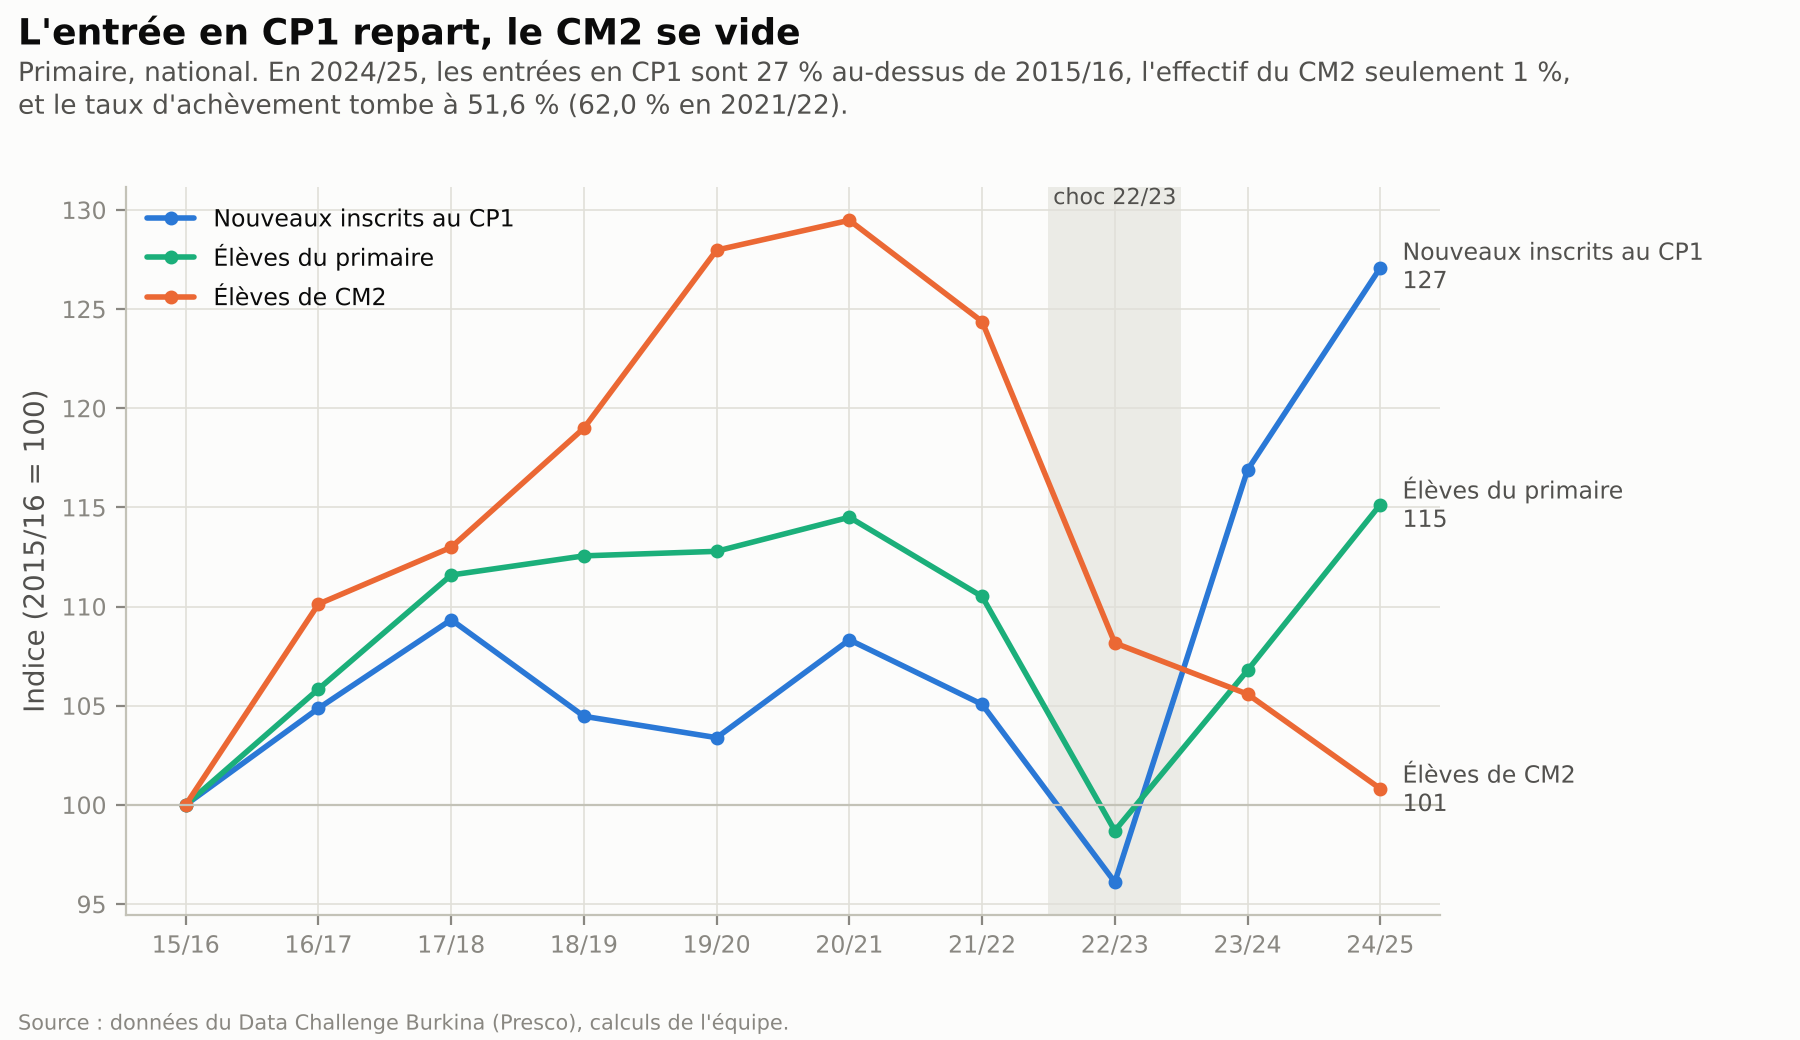

analyse/figures/02_achevement_par_region.png


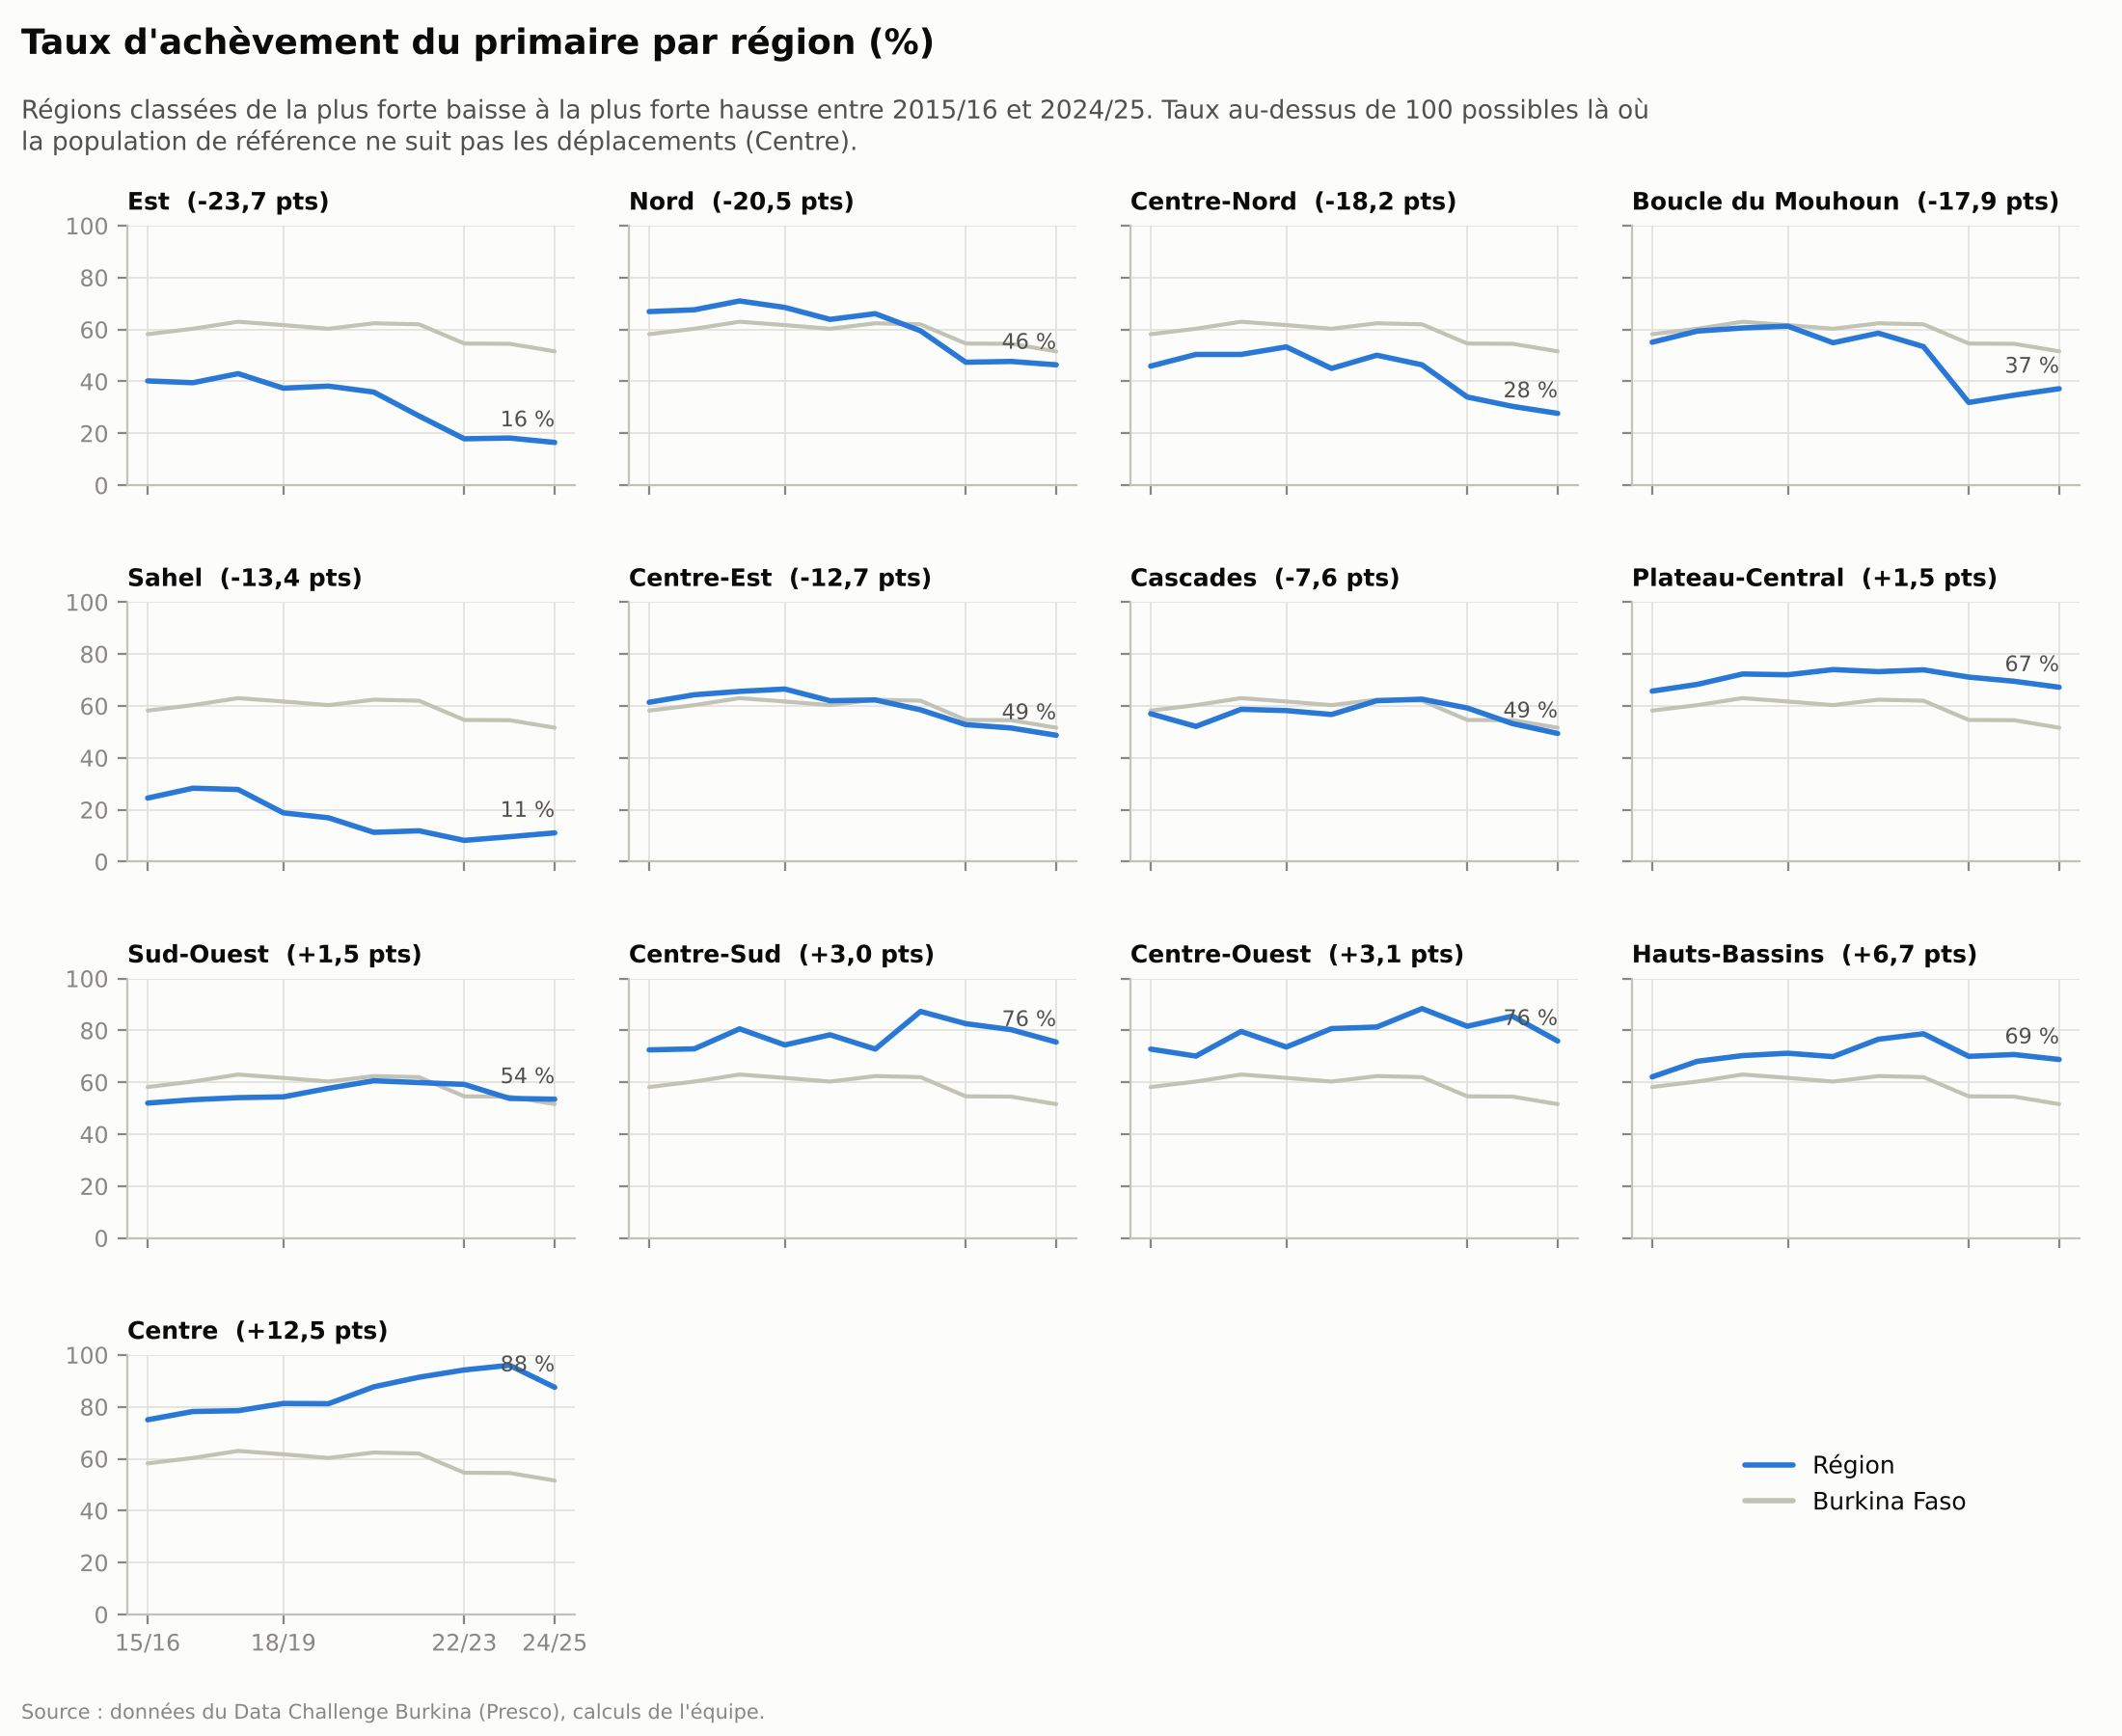

analyse/figures/03_sorties_en_exces.png


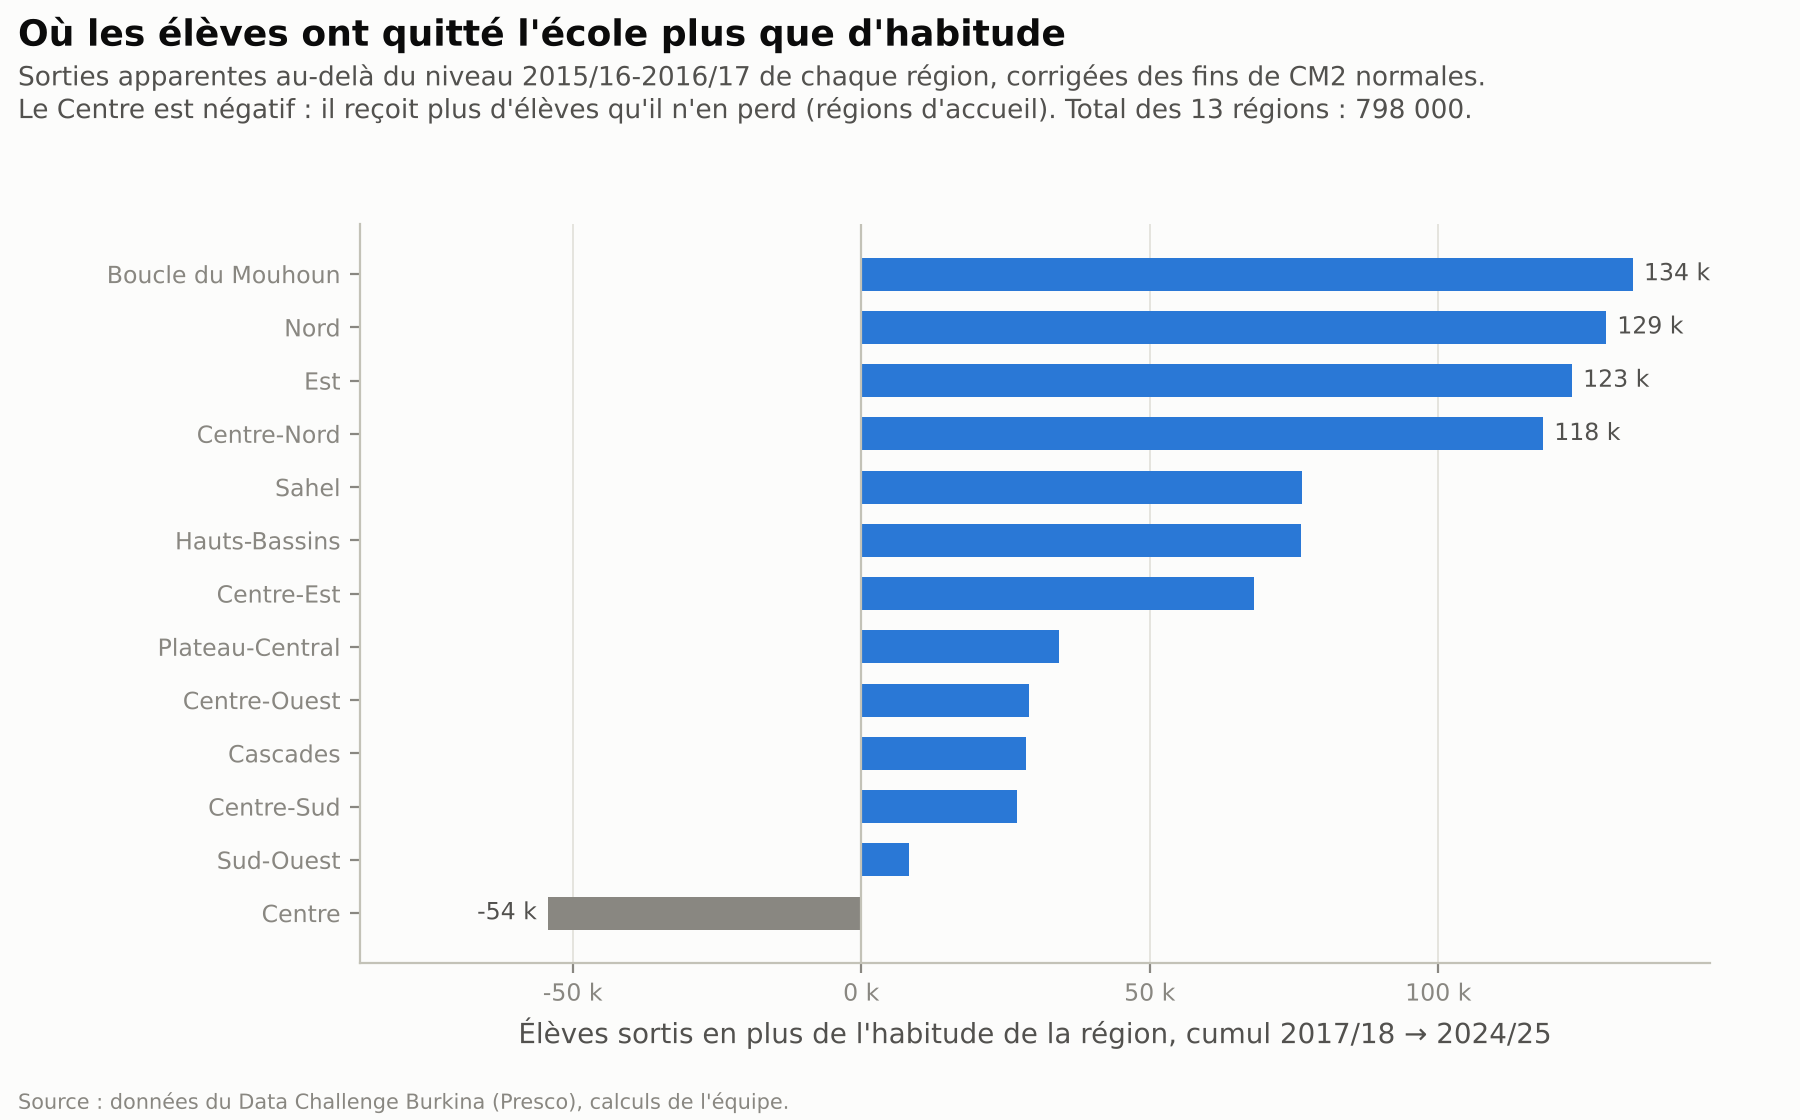

analyse/figures/04_ecoles_et_eleves.png


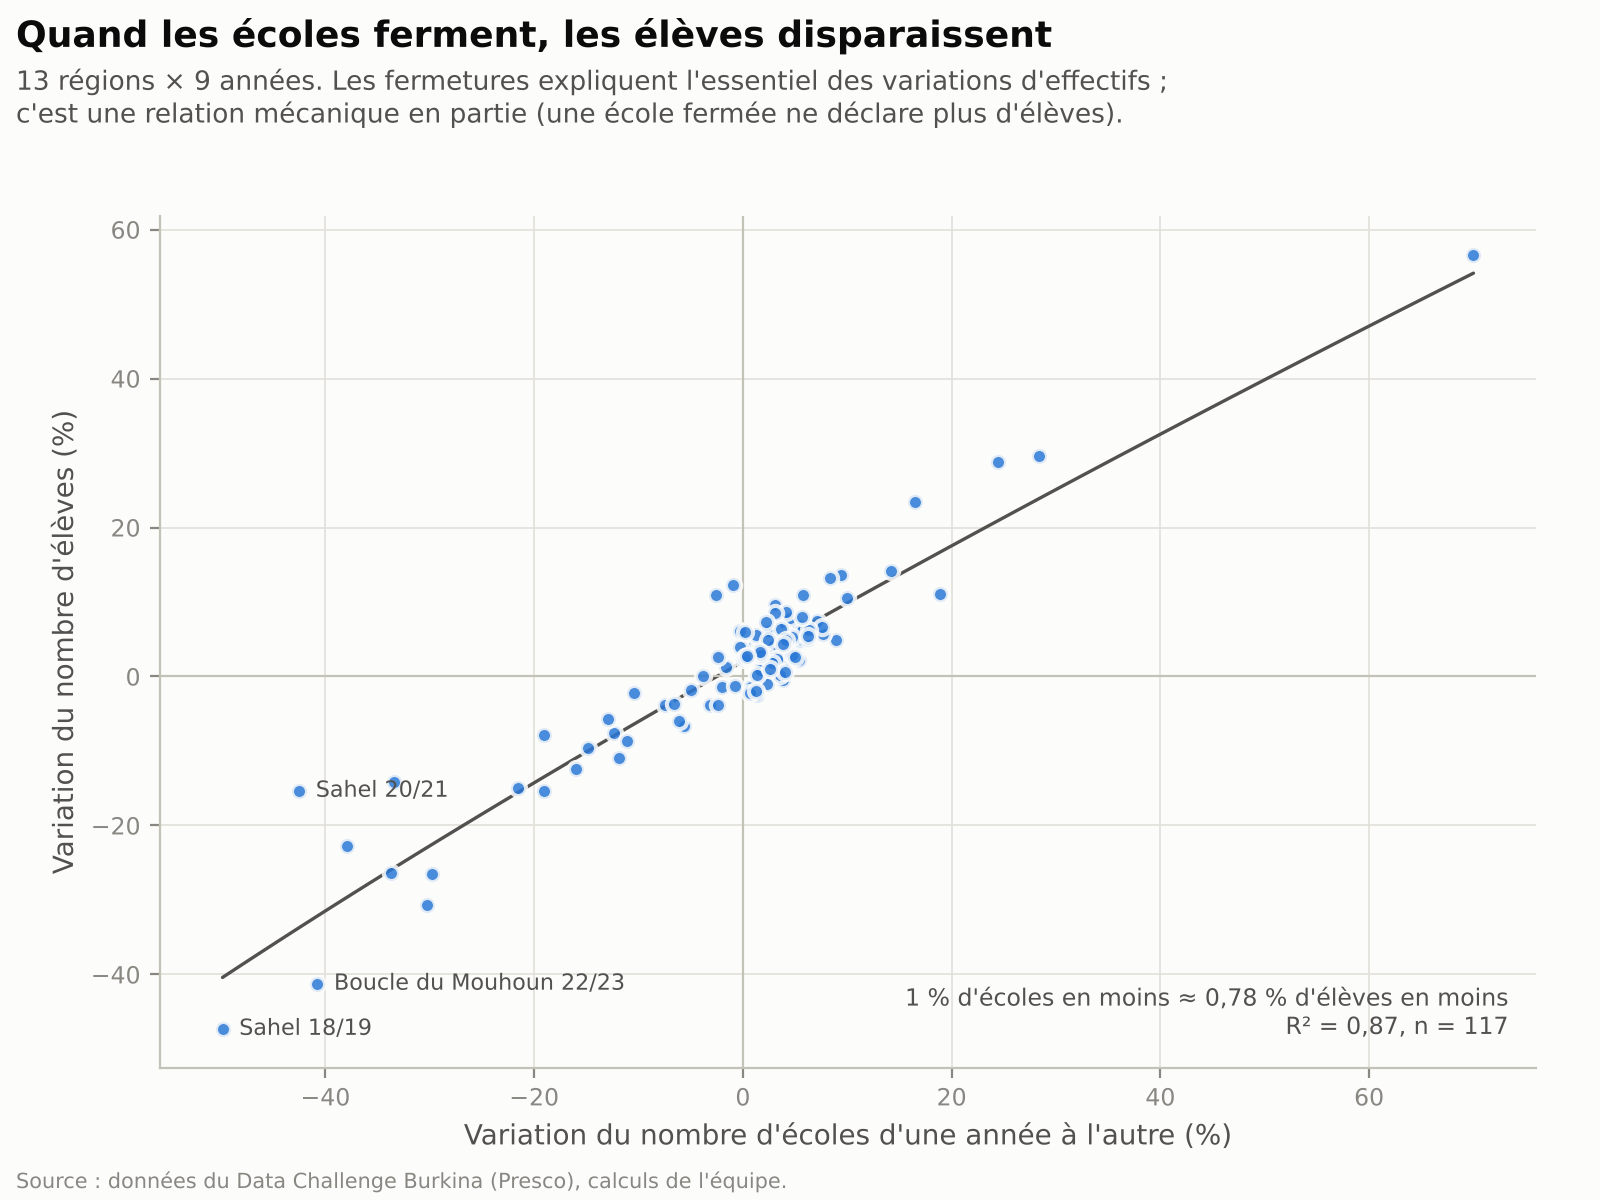

analyse/figures/05_contributions_recul_achevement.png


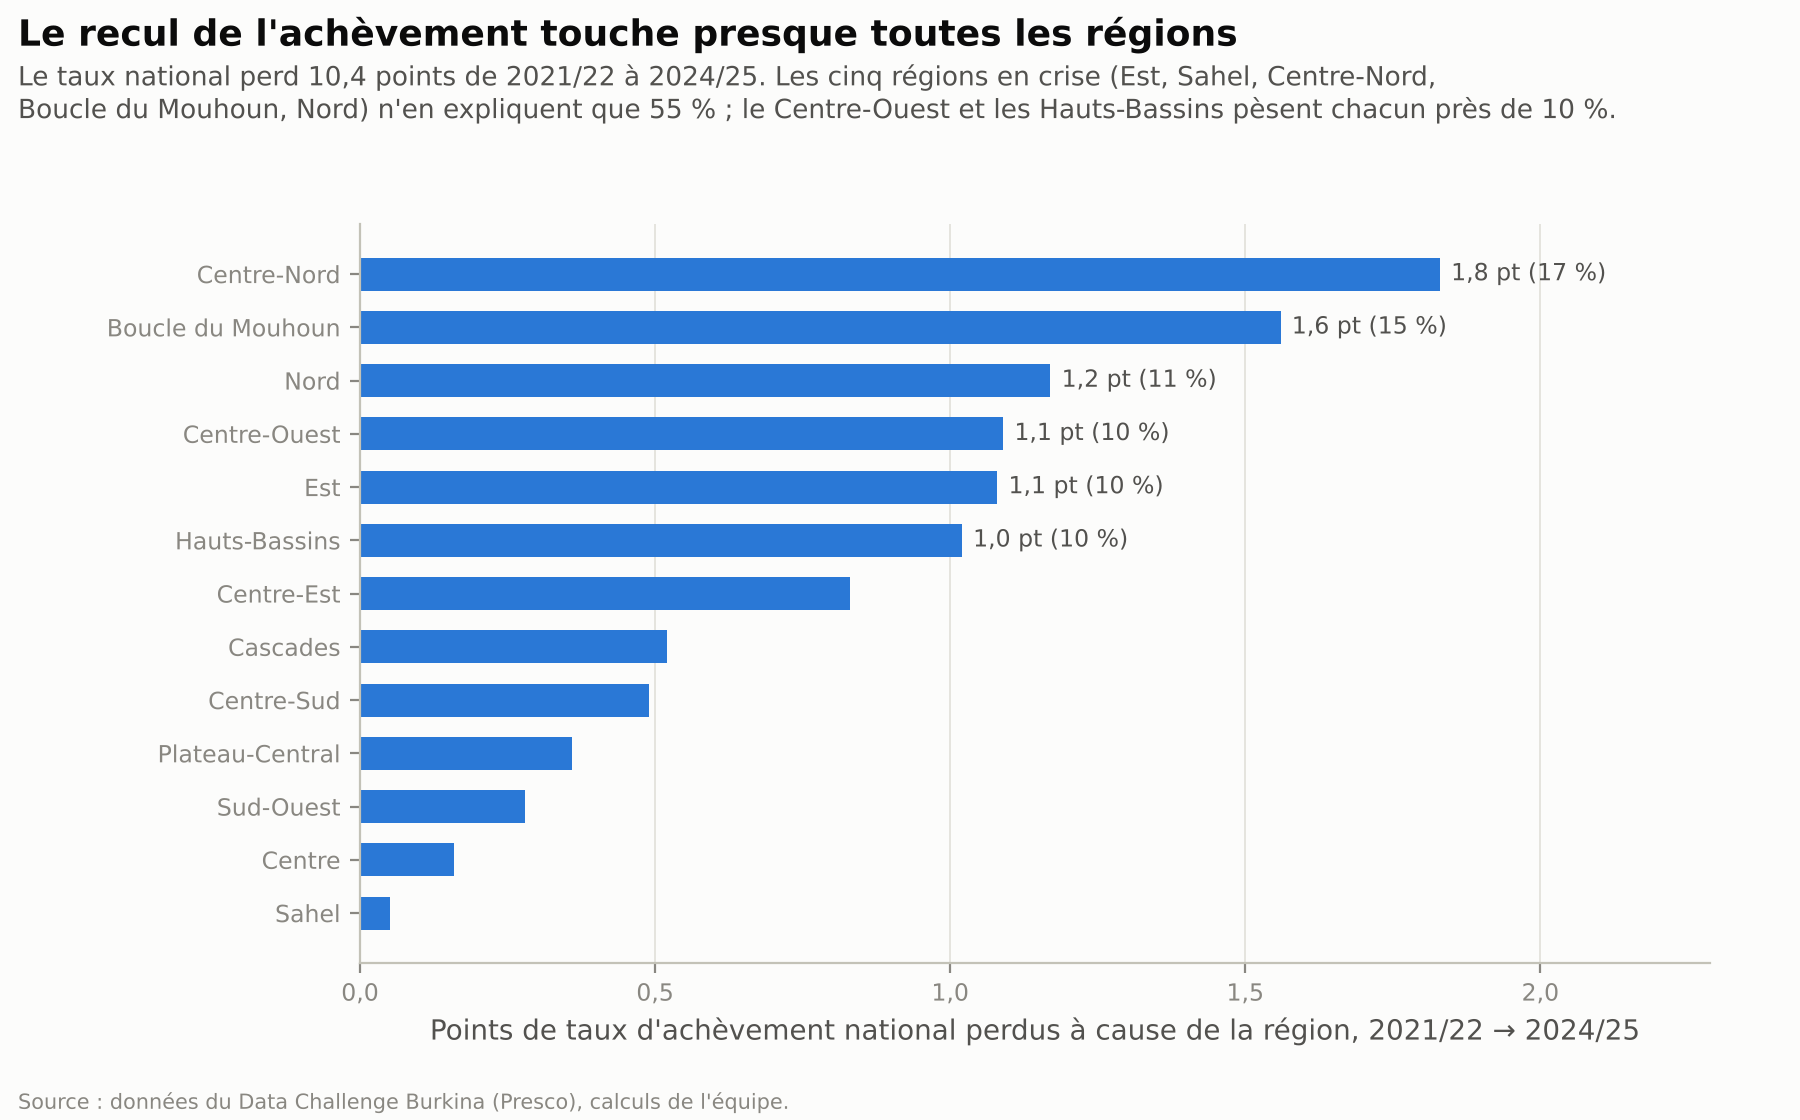

analyse/figures/06_garcons_filles.png


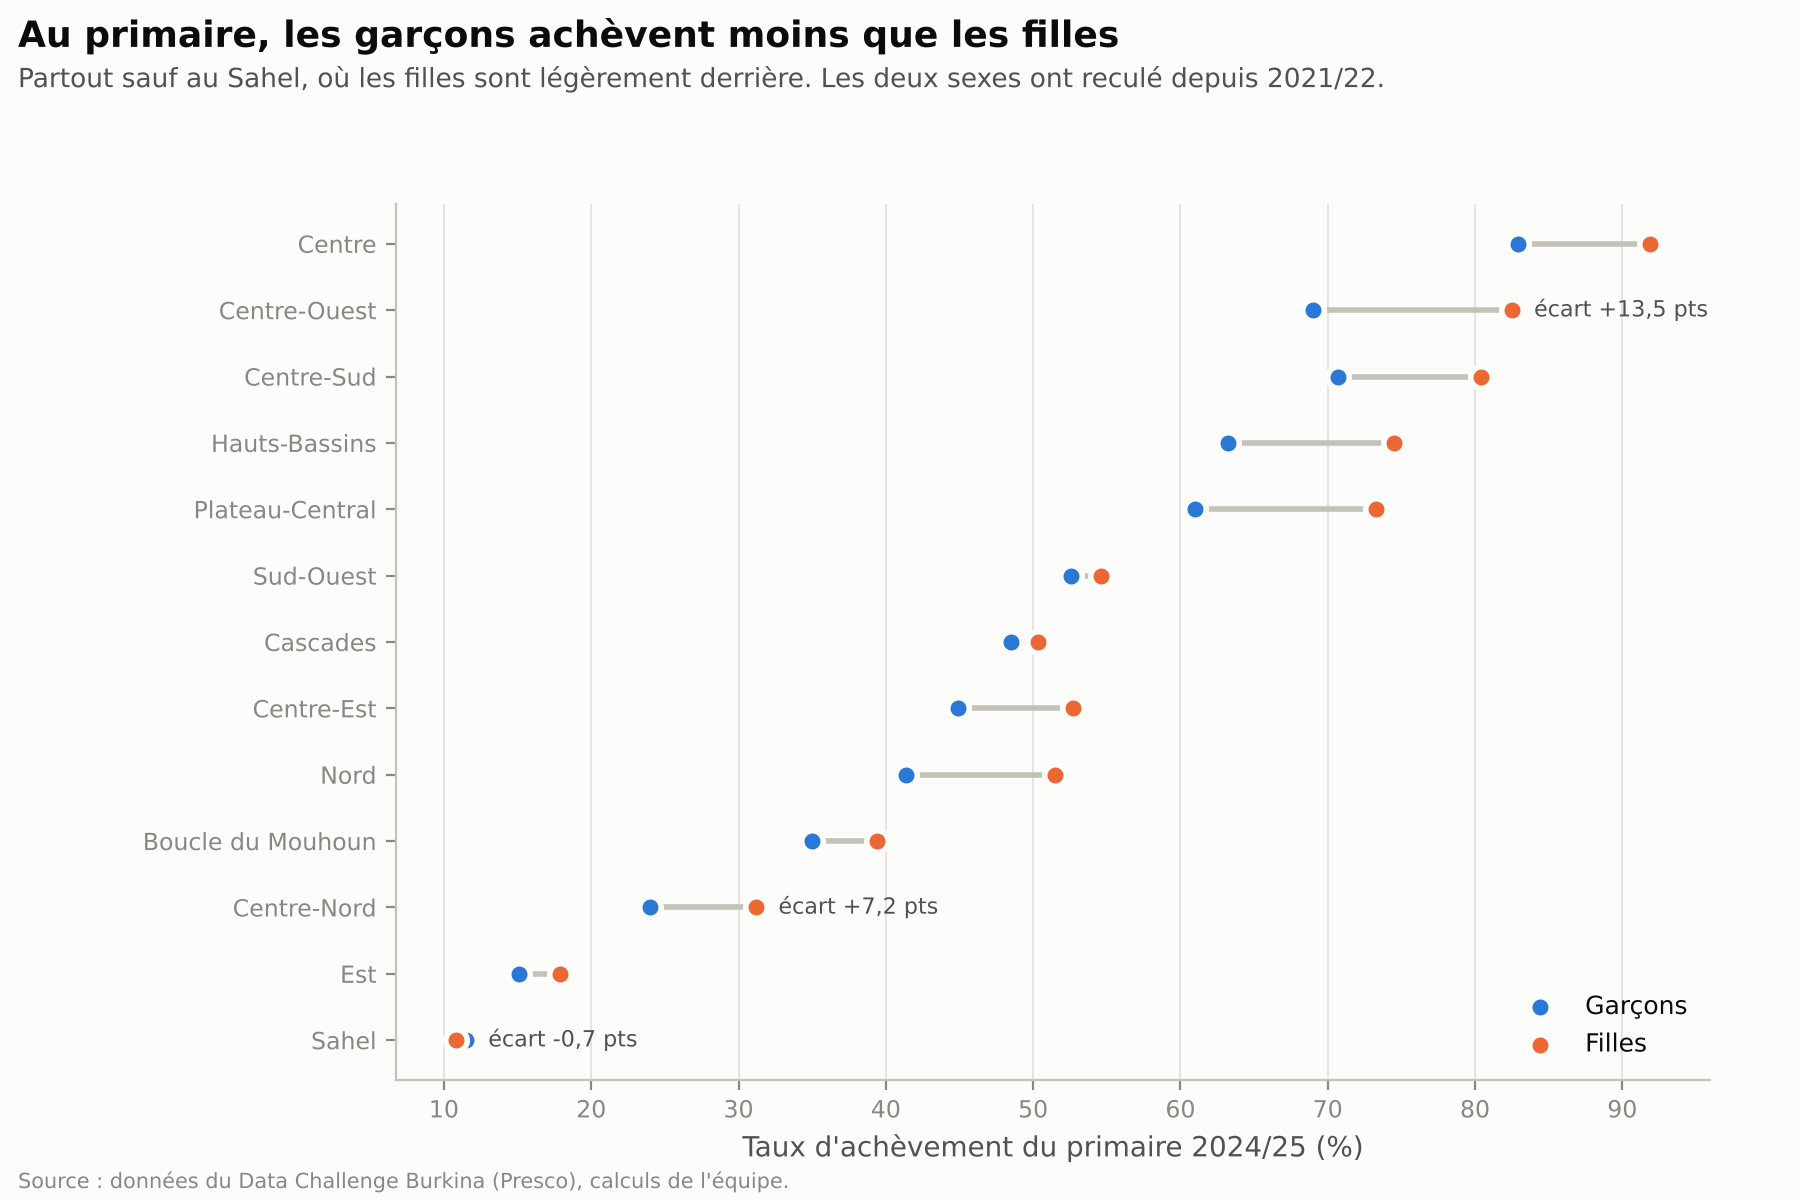

analyse/figures/07_prevision.png


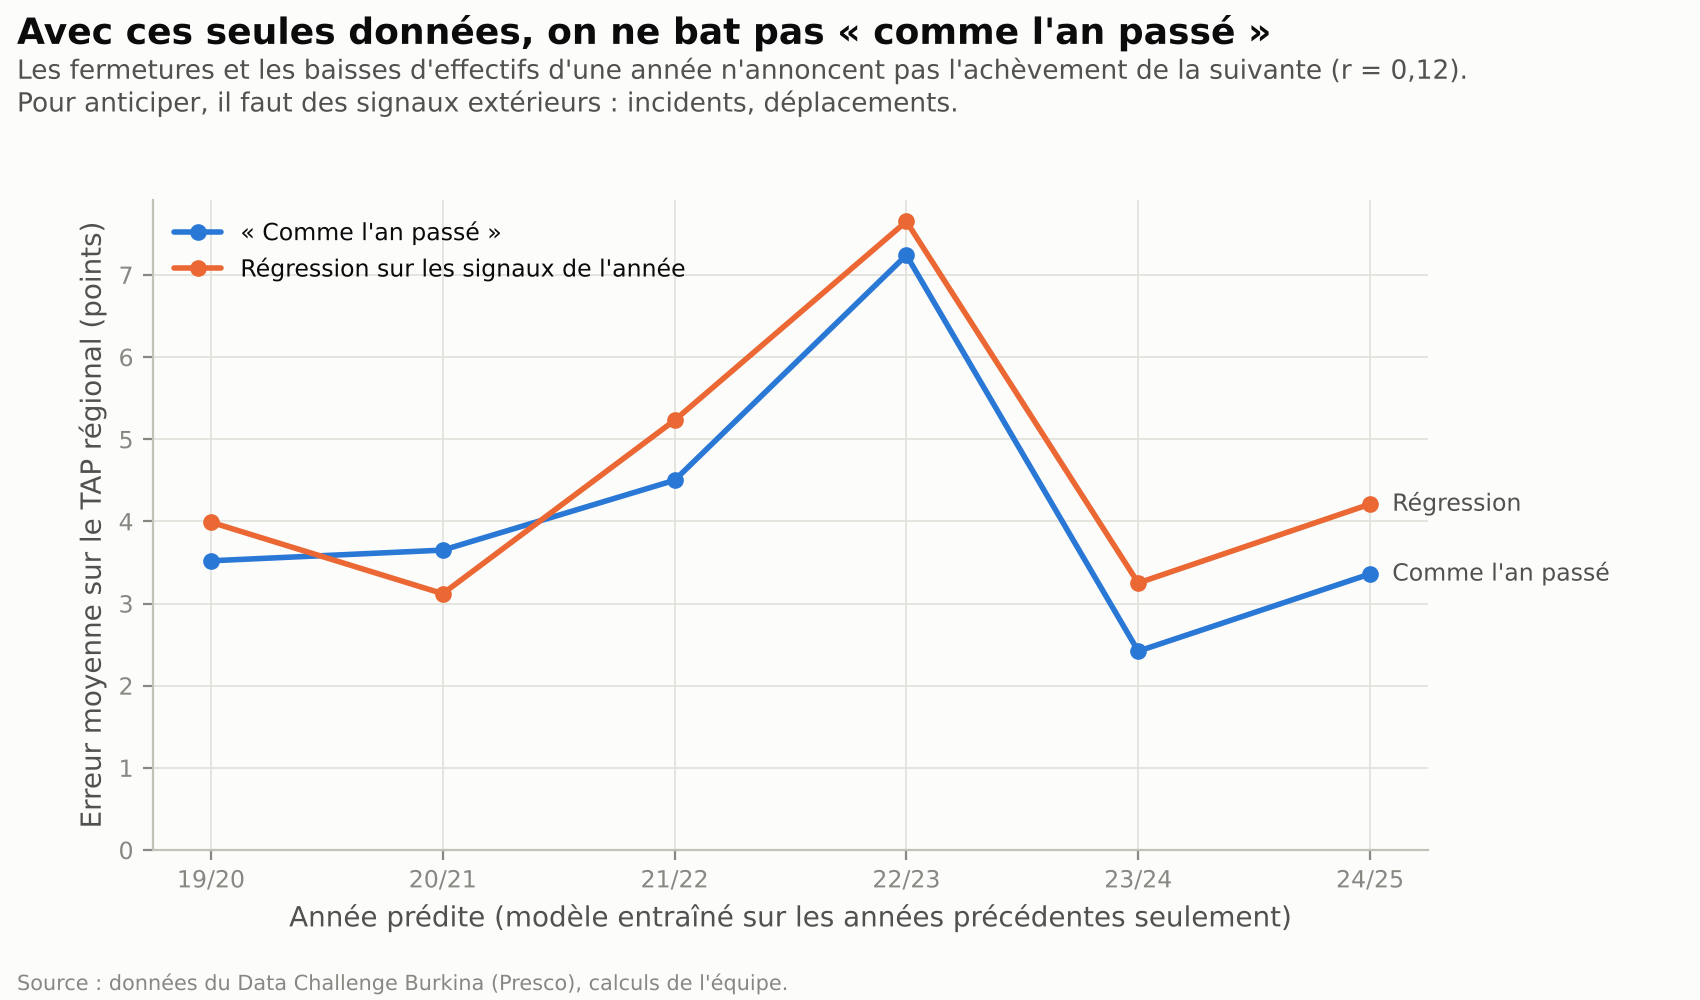

In [14]:
lancer_figures_pistes = main
t0 = time.time()
sys.argv = ['figures_pistes.py', 'data/tidy/presco_tidy.csv', 'analyse/', 'analyse/figures/']
lancer_figures_pistes()
montrer_figures(t0)